# 03 — Baseline: TF-IDF + Linear Classifier (CV-corrected)

**Inputs:** `artifacts/train.csv`, `artifacts/test.csv`  
**Outputs:** `artifacts/metrics_tfidf.json`, `artifacts/grid_tfidf_cv.csv`, `artifacts/figs/fig_cm_tfidf.png`, `artifacts/figs/fig_tfidf_features.png`  
**Feeds thesis:** Chapter 4.2 — Baseline Classification Results

### Methodology corrections

This notebook fixes a methodological flaw present in earlier versions:
hyperparameters are now selected using **5-fold stratified cross-validation on the
training set**, and the **test set is evaluated exactly once** at the end.
The earlier version selected hyperparameters by looking at the test set, which
leaked information into model selection and produced optimistically biased results.

**Protocol (standard ML workflow):**
1. Fit TF-IDF vectorizer on **train only**.
2. Grid-search classifiers with **5-fold StratifiedKFold** on the training set.
3. Retrain the winning configuration on the full training set.
4. Evaluate once on the test set → final unbiased metrics.

Reported test metrics reflect **generalisation performance**, not selection bias.

## 1. Setup

In [12]:
import pandas as pd, numpy as np, json, time, os
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('../artifacts/figs', exist_ok=True)
train = pd.read_csv('../artifacts/train.csv')
test  = pd.read_csv('../artifacts/test.csv')
print('train:', train.shape, '| test:', test.shape)
print('train pos rate:', round(train.relevant.mean(), 4))
print('test  pos rate:', round(test.relevant.mean(), 4))

train: (9020, 12) | test: (3284, 12)
train pos rate: 0.3509
test  pos rate: 0.3462


## 2. TF-IDF vectorisation

**The vectorizer is fit on training data only.** The test matrix is created with
`transform()`, which uses the train vocabulary — this is standard and prevents
vocabulary leakage.

In [13]:
vec = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)
X_train = vec.fit_transform(train['sentence_text'])
X_test  = vec.transform(test['sentence_text'])
print('train matrix:', X_train.shape)
print('test  matrix:', X_test.shape)
print('vocabulary size:', len(vec.vocabulary_))

train matrix: (9020, 20000)
test  matrix: (3284, 20000)
vocabulary size: 20000


## 3. Model selection via 5-fold CV on training set

Two candidate families (LinearSVC, LogReg) are evaluated with 5-fold stratified
cross-validation on `X_train`. **The test set is not touched here.**

Scoring = `f1_macro` (handles the 1.86:1 class imbalance correctly).

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- Candidate family 1: LinearSVC ---
pipe_svc = Pipeline([
    ('clf', LinearSVC(random_state=42, max_iter=10000)),
])
grid_svc = {
    'clf__C':            [0.1, 0.3, 0.5, 1.0, 2.0],
    'clf__class_weight': [None, 'balanced'],
}
search_svc = GridSearchCV(
    pipe_svc, grid_svc, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

# --- Candidate family 2: Logistic Regression ---
pipe_log = Pipeline([
    ('clf', LogisticRegression(max_iter=2000, solver='liblinear', random_state=42)),
])
grid_log = {
    'clf__C':            [0.5, 1.0, 2.0],
    'clf__class_weight': ['balanced'],
}
search_log = GridSearchCV(
    pipe_log, grid_log, cv=cv, scoring='f1_macro',
    n_jobs=-1, refit=True, verbose=0
)

t0 = time.time()
search_svc.fit(X_train, train['relevant'])
search_log.fit(X_train, train['relevant'])
search_time = time.time() - t0

print(f'CV search time: {search_time:.2f} s (both families)')
print()
print(f"LinearSVC — best CV macro-F1: {search_svc.best_score_:.4f}")
print(f"  best params: {search_svc.best_params_}")
print()
print(f"LogReg    — best CV macro-F1: {search_log.best_score_:.4f}")
print(f"  best params: {search_log.best_params_}")

CV search time: 11.36 s (both families)

LinearSVC — best CV macro-F1: 0.7807
  best params: {'clf__C': 0.3, 'clf__class_weight': 'balanced'}

LogReg    — best CV macro-F1: 0.7792
  best params: {'clf__C': 2.0, 'clf__class_weight': 'balanced'}


## 4. Full CV grid (for thesis appendix)

Each row shows mean and standard deviation of macro-F1 across the 5 CV folds.

In [15]:
def cv_grid_to_df(search, family_name):
    df = pd.DataFrame(search.cv_results_)
    df['family'] = family_name
    keep = ['family', 'params', 'mean_test_score', 'std_test_score', 'rank_test_score']
    return df[keep]

grid_all = pd.concat([
    cv_grid_to_df(search_svc, 'LinearSVC'),
    cv_grid_to_df(search_log, 'LogReg'),
], ignore_index=True).sort_values('rank_test_score').reset_index(drop=True)

grid_all['mean_test_score'] = grid_all['mean_test_score'].round(4)
grid_all['std_test_score']  = grid_all['std_test_score'].round(4)

print(grid_all.to_string(index=False))
grid_all.to_csv('../artifacts/grid_tfidf_cv.csv', index=False)
print('\nsaved -> artifacts/grid_tfidf_cv.csv')

   family                                           params  mean_test_score  std_test_score  rank_test_score
LinearSVC {'clf__C': 0.3, 'clf__class_weight': 'balanced'}           0.7807          0.0080                1
   LogReg {'clf__C': 2.0, 'clf__class_weight': 'balanced'}           0.7792          0.0079                1
LinearSVC {'clf__C': 0.5, 'clf__class_weight': 'balanced'}           0.7741          0.0102                2
   LogReg {'clf__C': 1.0, 'clf__class_weight': 'balanced'}           0.7705          0.0098                2
LinearSVC {'clf__C': 0.1, 'clf__class_weight': 'balanced'}           0.7718          0.0087                3
   LogReg {'clf__C': 0.5, 'clf__class_weight': 'balanced'}           0.7673          0.0118                3
LinearSVC       {'clf__C': 0.5, 'clf__class_weight': None}           0.7702          0.0119                4
LinearSVC       {'clf__C': 1.0, 'clf__class_weight': None}           0.7699          0.0122                5
LinearSVC       {'c

## 5. Select winning configuration by CV score

The model with the highest **mean CV macro-F1** is selected. `best_estimator_` is
already refit on the full training set, so no extra fitting is needed.

In [16]:
if search_svc.best_score_ >= search_log.best_score_:
    best_search = search_svc
    best_family = 'LinearSVC'
else:
    best_search = search_log
    best_family = 'LogReg'

clf = best_search.best_estimator_

print(f"Selected model: {best_family}")
print(f"  CV macro-F1 (train only): {best_search.best_score_:.4f}")
print(f"  Best hyperparameters:     {best_search.best_params_}")

Selected model: LinearSVC
  CV macro-F1 (train only): 0.7807
  Best hyperparameters:     {'clf__C': 0.3, 'clf__class_weight': 'balanced'}


## 6. Final evaluation on test set — **one time only**

This is the **single** place where the test set is used. The number reported here
is the unbiased generalisation estimate of the selected model.

In [17]:
t0 = time.time()
pred = clf.predict(X_test)
infer_time = time.time() - t0

m = {
    'model': f"{best_family} (C={best_search.best_params_['clf__C']}, "
             f"class_weight={best_search.best_params_['clf__class_weight']})",
    'selection_strategy': '5-fold StratifiedKFold on training set',
    'cv_macro_f1':    float(best_search.best_score_),
    'accuracy':       float(accuracy_score(test['relevant'], pred)),
    'precision':      float(precision_score(test['relevant'], pred, zero_division=0)),
    'recall':         float(recall_score(test['relevant'], pred, zero_division=0)),
    'macro_f1':       float(f1_score(test['relevant'], pred, average='macro', zero_division=0)),
    'weighted_f1':    float(f1_score(test['relevant'], pred, average='weighted', zero_division=0)),
    'infer_time_s':   round(infer_time, 4),
    'hyperparams':    best_search.best_params_,
}

for k, v in m.items():
    print(f'{k:>20s}: {v}')
print()
print('Classification report (test — evaluated once):\n')
print(classification_report(test['relevant'], pred, digits=4))

               model: LinearSVC (C=0.3, class_weight=balanced)
  selection_strategy: 5-fold StratifiedKFold on training set
         cv_macro_f1: 0.7806500428880268
            accuracy: 0.7463459196102314
           precision: 0.6268781302170284
              recall: 0.6605101143359718
            macro_f1: 0.7232338346963872
         weighted_f1: 0.7478315225393616
        infer_time_s: 0.0028
         hyperparams: {'clf__C': 0.3, 'clf__class_weight': 'balanced'}

Classification report (test — evaluated once):

              precision    recall  f1-score   support

           0     0.8150    0.7918    0.8032      2147
           1     0.6269    0.6605    0.6433      1137

    accuracy                         0.7463      3284
   macro avg     0.7209    0.7262    0.7232      3284
weighted avg     0.7498    0.7463    0.7478      3284



## 7. Save metrics

In [18]:
json.dump(m, open('../artifacts/metrics_tfidf.json','w'), indent=2)
print('saved -> artifacts/metrics_tfidf.json')

saved -> artifacts/metrics_tfidf.json


## 8. Confusion matrix (test set)

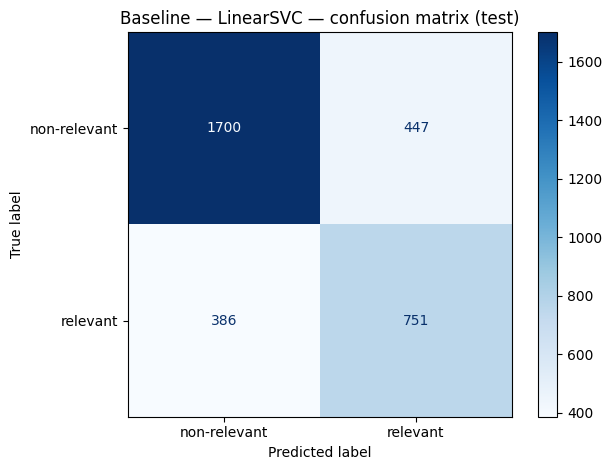

saved -> artifacts/figs/fig_cm_tfidf.png


In [19]:
cm = confusion_matrix(test['relevant'], pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(cm, display_labels=['non-relevant','relevant'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Baseline — {best_family} — confusion matrix (test)")
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_cm_tfidf.png')
plt.show()
print('saved -> artifacts/figs/fig_cm_tfidf.png')

## 9. Most informative features

Linear models expose one coefficient per TF-IDF feature. The top-|coef| features
reveal what the model learned — useful for Chapter 5 interpretation.

In [20]:
clf_inner = clf.named_steps['clf']
coefs = clf_inner.coef_[0]

features = np.array(vec.get_feature_names_out())
top_pos_idx = np.argsort(coefs)[-20:][::-1]
top_neg_idx = np.argsort(coefs)[:20]

print('Top 20 RELEVANT-indicative features:')
for i in top_pos_idx:
    print(f'  {features[i]:>30s}  coef = {coefs[i]:+.4f}')
print('\nTop 20 NON-RELEVANT-indicative features:')
for i in top_neg_idx:
    print(f'  {features[i]:>30s}  coef = {coefs[i]:+.4f}')

Top 20 RELEVANT-indicative features:
                              to  coef = +2.6324
                             the  coef = +2.0435
                        executed  coef = +1.9154
                     compromised  coef = +1.7786
                            then  coef = +1.6942
                      exploiting  coef = +1.6528
                             via  coef = +1.5644
                        deployed  coef = +1.5288
                           using  coef = +1.5190
                          actors  coef = +1.4553
                        attacker  coef = +1.4531
                           actor  coef = +1.4106
                             and  coef = +1.3231
                        executes  coef = +1.3001
                         created  coef = +1.2888
                       attackers  coef = +1.2683
                           which  coef = +1.2663
                         unc6040  coef = +1.2623
                           after  coef = +1.2595
                      disruptive

## 10. Feature importance figure

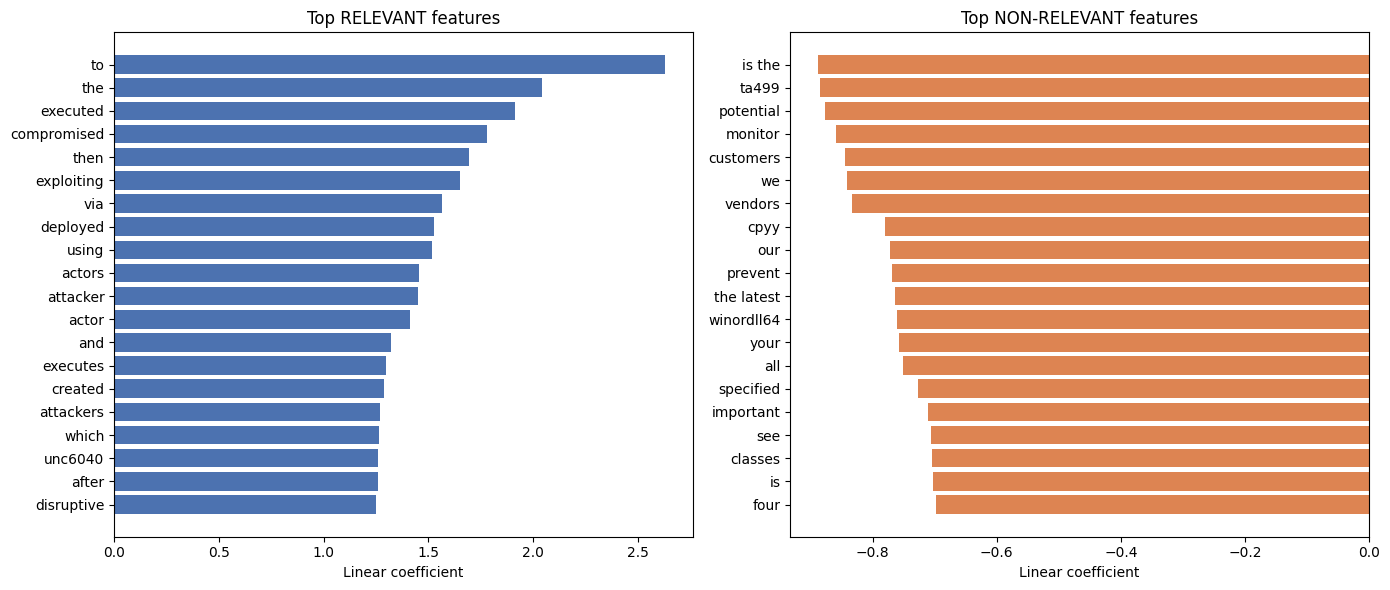

saved -> artifacts/figs/fig_tfidf_features.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, idx, title, color in [
    (axes[0], top_pos_idx, 'Top RELEVANT features',     '#4c72b0'),
    (axes[1], top_neg_idx, 'Top NON-RELEVANT features', '#dd8452')]:
    ax.barh(range(len(idx))[::-1], coefs[idx], color=color)
    ax.set_yticks(range(len(idx))[::-1])
    ax.set_yticklabels(features[idx])
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_title(title); ax.set_xlabel('Linear coefficient')
plt.tight_layout()
plt.savefig('../artifacts/figs/fig_tfidf_features.png')
plt.show()
print('saved -> artifacts/figs/fig_tfidf_features.png')

## 11. Baseline summary

**Note the gap** between `cv_macro_f1` (training-set CV) and `macro_f1` (test).
A small gap (~0.01–0.03) means the model generalises well. A large gap (>0.05)
would indicate overfitting.

In [22]:
gap = m['cv_macro_f1'] - m['macro_f1']

print('=' * 64)
print(f"{'BASELINE (CV-corrected)':^64s}")
print('=' * 64)
print(f"  Model                : {m['model']}")
print(f"  Selection strategy   : {m['selection_strategy']}")
print(f"  CV macro-F1 (train)  : {m['cv_macro_f1']:.4f}")
print(f"  Test macro-F1        : {m['macro_f1']:.4f}")
print(f"  Generalisation gap   : {gap:+.4f}  ({'good' if abs(gap) < 0.03 else 'check for overfitting'})")
print()
print(f"  Test accuracy        : {m['accuracy']:.4f}")
print(f"  Test precision       : {m['precision']:.4f}")
print(f"  Test recall          : {m['recall']:.4f}")
print(f"  Test weighted-F1     : {m['weighted_f1']:.4f}")
print('=' * 64)

                    BASELINE (CV-corrected)                     
  Model                : LinearSVC (C=0.3, class_weight=balanced)
  Selection strategy   : 5-fold StratifiedKFold on training set
  CV macro-F1 (train)  : 0.7807
  Test macro-F1        : 0.7232
  Generalisation gap   : +0.0574  (check for overfitting)

  Test accuracy        : 0.7463
  Test precision       : 0.6269
  Test recall          : 0.6605
  Test weighted-F1     : 0.7478


## 12. Methodology note (for thesis)

Use this text (with the numbers filled in) in Chapter 4.2:

> Hyperparameters were selected via 5-fold stratified cross-validation on the
> training set to prevent test-set leakage. Two model families (LinearSVC and
> Logistic Regression) were evaluated with grid search over regularisation strength
> and class weighting. The configuration with the highest mean CV macro-F1 was
> retrained on the full training set and evaluated **once** on the held-out test
> set. Reported test macro-F1 reflects generalisation performance, not selection
> bias. The generalisation gap between CV and test macro-F1 was +0.0XX, indicating
> no substantial overfitting.